# Introdução ao Random Forest em Ciência de Dados

As **árvores de decisão** são algoritmos de aprendizado de máquina amplamente utilizados devido à sua simplicidade e interpretabilidade. Elas funcionam dividindo o conjunto de dados em subconjuntos menores com base em testes sobre os atributos, formando uma estrutura semelhante a uma árvore que leva a decisões finais nas folhas. No entanto, apesar de suas vantagens, as árvores de decisão individuais podem sofrer de **overfitting** e instabilidade. Para superar essas limitações, surge o **Random Forest**, uma técnica de ensemble que combina múltiplas árvores de decisão para melhorar a precisão e robustez das previsões.

## Revisão: Fundamentos das Árvores de Decisão

### Como Funcionam as Árvores de Decisão?

- **Divisão Recursiva:** As árvores de decisão dividem os dados em subconjuntos cada vez menores através de testes baseados nos atributos.
- **Nós e Folhas:**
  - **Nós Internos:** Representam testes ou condições sobre os atributos.
  - **Ramos:** Correspondem aos resultados dos testes.
  - **Nós Folha:** Indicam a decisão final ou previsão.
- **Critérios de Divisão:** Utilizam métricas como **Índice Gini** e **Entropia** para escolher os melhores atributos para dividir os dados.

### Vantagens das Árvores de Decisão

- **Fácil Interpretação:** A lógica de decisão é clara e pode ser visualizada.
- **Flexibilidade:** Lida com dados numéricos e categóricos.
- **Pouco Pré-processamento:** Não requer normalização ou padronização dos dados.

### Limitações das Árvores de Decisão

- **Overfitting:** Árvores profundas podem se ajustar muito aos dados de treinamento, capturando ruídos.
- **Instabilidade:** Pequenas variações nos dados podem alterar significativamente a estrutura da árvore.
- **Bias para Atributos com Muitos Níveis:** Atributos com muitos valores únicos podem dominar a estrutura da árvore.



## Introdução ao Random Forest

### O Que é o Random Forest?

O **Random Forest** é um algoritmo de aprendizado de máquina que combina múltiplas árvores de decisão para formar um modelo mais poderoso e preciso. É um tipo de **ensemble method**, especificamente um **bagging** (Bootstrap Aggregating), que constrói várias árvores de decisão independentes e as combina através de uma média (para regressão) ou votação majoritária (para classificação).

### Por Que Usar o Random Forest?

- **Redução de Overfitting:** Ao combinar várias árvores, o modelo geral é menos propenso a overfitting.
- **Melhoria da Precisão:** As previsões combinadas de múltiplas árvores geralmente são mais precisas do que as de uma única árvore.
- **Robustez:** É menos sensível a variações nos dados de treinamento.

## Como o Random Forest Funciona?

### 1. Bootstrap Sampling (Amostragem com Reposição)

- Para cada árvore na floresta:
  - **Amostra Aleatória:** Uma amostra aleatória com reposição é retirada do conjunto de dados original.
  - **Independência:** Cada árvore é treinada em um conjunto de dados ligeiramente diferente.

### 2. Seleção Aleatória de Atributos

- **Na Construção de Cada Nó:**
  - Em vez de considerar todos os atributos para a melhor divisão, o algoritmo seleciona aleatoriamente um subconjunto de atributos.
  - **Diversidade:** Isso promove a diferença entre as árvores, tornando o ensemble mais robusto.

### 3. Construção das Árvores

- **Árvores Profundas e Não Podadas:**
  - Cada árvore é geralmente crescida ao máximo possível sem poda.
  - Isso contribui para a baixa correlação entre as árvores.

### 4. Agregação das Previsões

- **Classificação:**
  - A classe final é determinada pela **votação majoritária** das previsões de todas as árvores.
- **Regressão:**
  - A previsão final é a **média** das previsões individuais das árvores.

## Exemplo Ilustrativo

Imagine que queremos prever se um e-mail é **"Spam"** ou **"Não Spam"**.

1. **Criação de Múltiplas Árvores:**
   - Cada árvore é treinada em um conjunto de e-mails selecionado aleatoriamente com reposição.
   - Em cada divisão, apenas um subconjunto aleatório de palavras (atributos) é considerado.

2. **Previsão:**
   - Para um novo e-mail, cada árvore faz sua previsão (**"Spam"** ou **"Não Spam"**).
   - A classe final é determinada pela maioria das previsões.

## Vantagens do Random Forest

- **Alta Precisão:** Geralmente alcança melhor desempenho do que uma única árvore.
- **Resistente a Overfitting:** A combinação de múltiplas árvores reduz a variância do modelo.
- **Importância das Variáveis:** Fornece estimativas sobre a importância de cada atributo no modelo.

## Desvantagens do Random Forest

- **Menor Interpretabilidade:** Difícil de interpretar o modelo como um todo, embora seja possível analisar a importância das variáveis.
- **Maior Custo Computacional:** Treinar múltiplas árvores aumenta o tempo de processamento e uso de memória.
- **Previsões Lentas:** Pode ser mais lento ao fazer previsões, especialmente com um grande número de árvores.


## Hiperparâmetros de destaque

- **Escolha do Número de Árvores (n_estimators):**
  - Um número maior de árvores pode melhorar a performance até certo ponto, mas aumenta o custo computacional.
- **Seleção de Atributos em Cada Divisão (max_features):**
  - Em problemas de classificação, um valor comum é a raiz quadrada do número total de atributos.
  - Em regressão, costuma-se usar um terço do número total de atributos.
- **Parâmetros de Profundidade:**
  - Embora as árvores sejam geralmente crescidas ao máximo, limitar a profundidade pode ser útil em alguns casos para reduzir o tempo de treinamento.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
    fbeta_score,
    precision_recall_curve,
    precision_score,
    PrecisionRecallDisplay,
    recall_score,
    roc_auc_score,
    roc_curve,
    RocCurveDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# estudo árvores
from sklearn.inspection import permutation_importance
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.ensemble import RandomForestClassifier

from src.config import DADOS_LIMPOS
from src.models import RANDOM_STATE

sns.set_theme(palette="bright", style="white")

In [2]:
df = pd.read_parquet(DADOS_LIMPOS)

df.head()

,area_mean,area_se,area_worst,compactness_mean,compactness_se,compactness_worst,concave points_mean,concave points_se,concave points_worst,concavity_mean,...,radius_worst,smoothness_mean,smoothness_se,smoothness_worst,symmetry_mean,symmetry_se,symmetry_worst,texture_mean,texture_se,texture_worst
0,1001.0,153.40,2019.0,0.27760,0.04904,0.6656,0.14710,0.01587,0.2654,0.3001,...,25.38,0.11840,0.006399,0.1622,0.2419,0.03003,0.4601,10.38,0.9053,17.33
1,1326.0,74.08,1956.0,0.07864,0.01308,0.1866,0.07017,0.01340,0.1860,0.0869,...,24.99,0.08474,0.005225,0.1238,0.1812,0.01389,0.2750,17.77,0.7339,23.41
2,1203.0,94.03,1709.0,0.15990,0.04006,0.4245,0.12790,0.02058,0.2430,0.1974,...,23.57,0.10960,0.006150,0.1444,0.2069,0.02250,0.3613,21.25,0.7869,25.53
3,386.1,27.23,567.7,0.28390,0.07458,0.8663,0.10520,0.01867,0.2575,0.2414,...,14.91,0.14250,0.009110,0.2098,0.2597,0.05963,0.6638,20.38,1.1560,26.50
4,1297.0,94.44,1575.0,0.13280,0.02461,0.2050,0.10430,0.01885,0.1625,0.1980,...,22.54,0.10030,0.011490,0.1374,0.1809,0.01756,0.2364,14.34,0.7813,16.67


In [3]:
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

In [4]:
y.head()

0    M
1    M
2    M
3    M
4    M
Name: diagnosis, dtype: object

In [5]:
le = LabelEncoder()

y = le.fit_transform(y)

y[:10]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [6]:
le.classes_

array(['B', 'M'], dtype=object)

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

In [8]:
np.bincount(y_train) / len(y_train)

array([0.62676056, 0.37323944])

In [9]:
np.bincount(y_test) / len(y_test)

array([0.62937063, 0.37062937])

In [10]:
# mudar nosso classificador
clf = RandomForestClassifier(random_state=RANDOM_STATE)

clf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [11]:
y_pred = clf.predict(X_test)

In [12]:
clf.score(X_test, y_test)

0.958041958041958

O `score` do classificador retorna a acurácia do modelo, que é a proporção de predições corretas feitas pelo modelo. Podemos calcular a acurácia comparando as predições feitas pelo modelo com as respostas corretas. A acurácia é dada por:

$$
\text{acurácia} = \frac{\text{número de predições corretas}}{\text{número total de predições}} 
$$

Uma acurácia de 1.0 significa que o modelo fez todas as predições corretas, enquanto uma acurácia de 0.0 significa que o modelo fez todas as predições erradas.

In [13]:
accuracy_score(y_test, y_pred)

0.958041958041958

### Matriz de confusão

A matriz de confusão é uma tabela que mostra o número de predições corretas e incorretas feitas pelo modelo. A matriz de confusão é dada por (considerando a ordem do Scikit-Learn):

$$
\begin{array}{|c|c|c|}
\hline
& \text{predição negativa} & \text{predição positiva} \\
\hline
\text{classe negativa} & TN & FP \\
\hline
\text{classe positiva} & FN & TP \\
\hline
\end{array}
$$


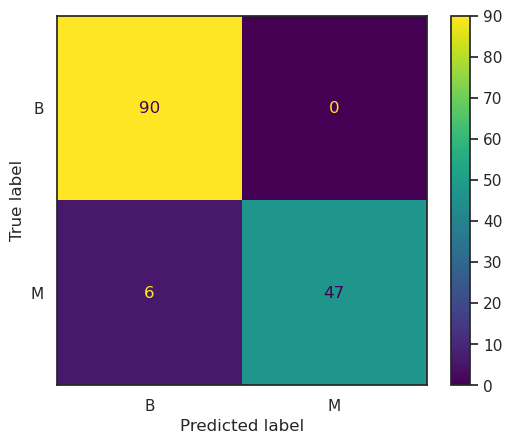

In [14]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=le.classes_)

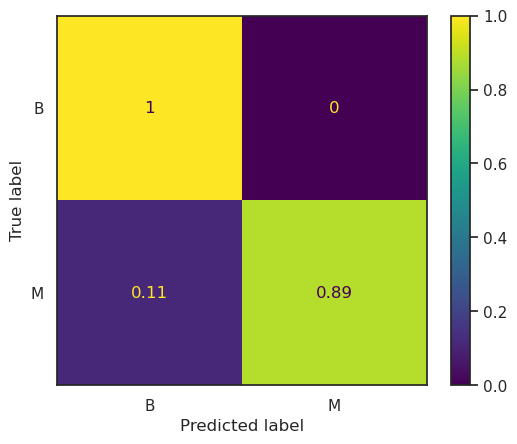

In [15]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=le.classes_, normalize="true")

### Recall

Uma outra métrica que podemos usar para avaliar a qualidade de um modelo de classificação é o recall. O recall é a proporção de exemplos da classe positiva que foram corretamente classificados pelo modelo. O recall é dado por:

$$
\text{recall} = \frac{TP}{P} = \frac{TP}{TP + FN}
$$

In [16]:
recall_score(y_test, y_pred)

0.8867924528301887

### Precision (Precisão)

A precisão é a proporção de exemplos classificados como positivos que são realmente positivos. A precisão é dada por:

$$
\text{precisão} = \frac{TP}{\text{pred }P} = \frac{TP}{TP + FP}
$$



In [17]:
precision_score(y_test, y_pred)

1.0

### F Score

O F1 score é a média harmônica entre recall e precisão. A média harmônica é usada ao invés da média aritmética porque penaliza valores extremos. O F1 score é dado por:

$$
\text{F1 score} = 2 \times \frac{\text{precisão} \times \text{recall}}{\text{precisão} + \text{recall}}
$$

Por ser uma média harmônica, o F1 score é mais sensível a valores baixos de precisão ou recall. Por exemplo, se tivermos um modelo que tem precisão 1.0 e recall 0.0, o F1 score será 0.0. Se tivermos um modelo que tem precisão 0.0 e recall 1.0, o F1 score também será 0.0.




In [18]:
f1_score(y_test, y_pred)

0.94

O F1 score é um caso especial da média $F_\beta$:

$$
F_\beta = (1 + \beta^2) \times \frac{\text{precisão} \times \text{recall}}{\beta^2 \times \text{precisão} + \text{recall}}
$$

Quando $\beta = 1$, temos o F1 score. Quando $\beta > 1$, o recall tem mais peso na média. Quando $\beta < 1$, a precisão tem mais peso na média.

In [19]:
fbeta_score(y_test, y_pred, beta=0.5)

0.975103734439834

In [20]:
fbeta_score(y_test, y_pred, beta=2)

0.9073359073359073

### Curva ROC

A curva ROC (Receiver Operating Characteristic) é uma curva que mostra a taxa de verdadeiros positivos (recall) em função da taxa de falsos positivos. A curva ROC é útil para avaliar a qualidade de um classificador binário em diferentes thresholds. A área sob a curva ROC (AUC) é uma métrica que varia entre 0.0 e 1.0, onde 0.0 significa um classificador ruim e 1.0 significa um classificador perfeito.



In [21]:
roc_auc = roc_auc_score(y_test, y_pred)
roc_auc

0.9433962264150944

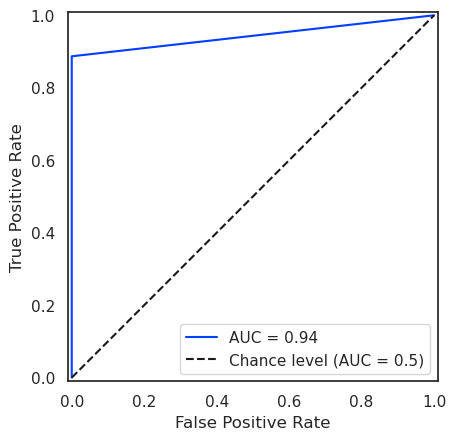

In [22]:
fpr, tpr, limiares = roc_curve(y_test, y_pred)

disp = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc)
disp.plot(plot_chance_level=True)

### Curva Precision-Recall

A curva precision-recall é uma curva que mostra a precisão em função do recall. A curva precision-recall é útil para avaliar a qualidade de um classificador binário em diferentes thresholds. A área sob a curva precision-recall (AUC) é uma métrica que varia entre 0.0 e 1.0, onde 0.0 significa um classificador ruim e 1.0 significa um classificador perfeito.



In [23]:
average_precision = average_precision_score(y_test, y_pred)
average_precision

0.9287504947882307

In [24]:
y_test.mean()

0.3706293706293706

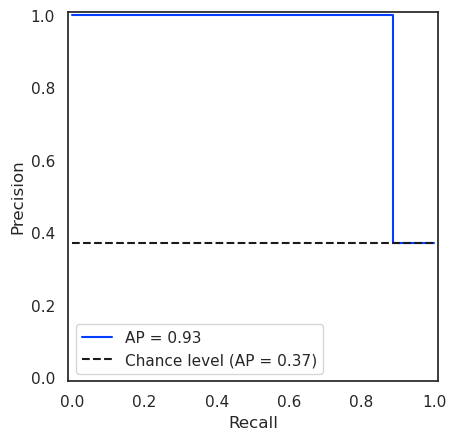

In [25]:
precision, recall, limiares = precision_recall_curve(y_test, y_pred)

disp = PrecisionRecallDisplay(
    precision=precision,
    recall=recall,
    average_precision=average_precision,
    prevalence_pos_label=y_test.mean()
)

disp.plot(plot_chance_level=True)

A reta de nível de chance no gráfico de Precision-Recall representa a precisão esperada de um classificador aleatório que faz previsões positivas independentemente das características dos dados.

É a linha que indica o desempenho de um modelo que adivinha aleatoriamente as classes dos exemplos, seguindo a mesma prevalência da classe positiva no conjunto de dados. Serve como uma linha de base para comparar o desempenho do seu modelo. Se o seu modelo não superar essa linha, ele não está melhor do que uma classificação aleatória.

### Classification Report

In [26]:
print(classification_report(y_test, y_pred, target_names=le.classes_))

              precision    recall  f1-score   support

           B       0.94      1.00      0.97        90
           M       1.00      0.89      0.94        53

    accuracy                           0.96       143
   macro avg       0.97      0.94      0.95       143
weighted avg       0.96      0.96      0.96       143



## Visualizações e análises específicas para árvores de decisão

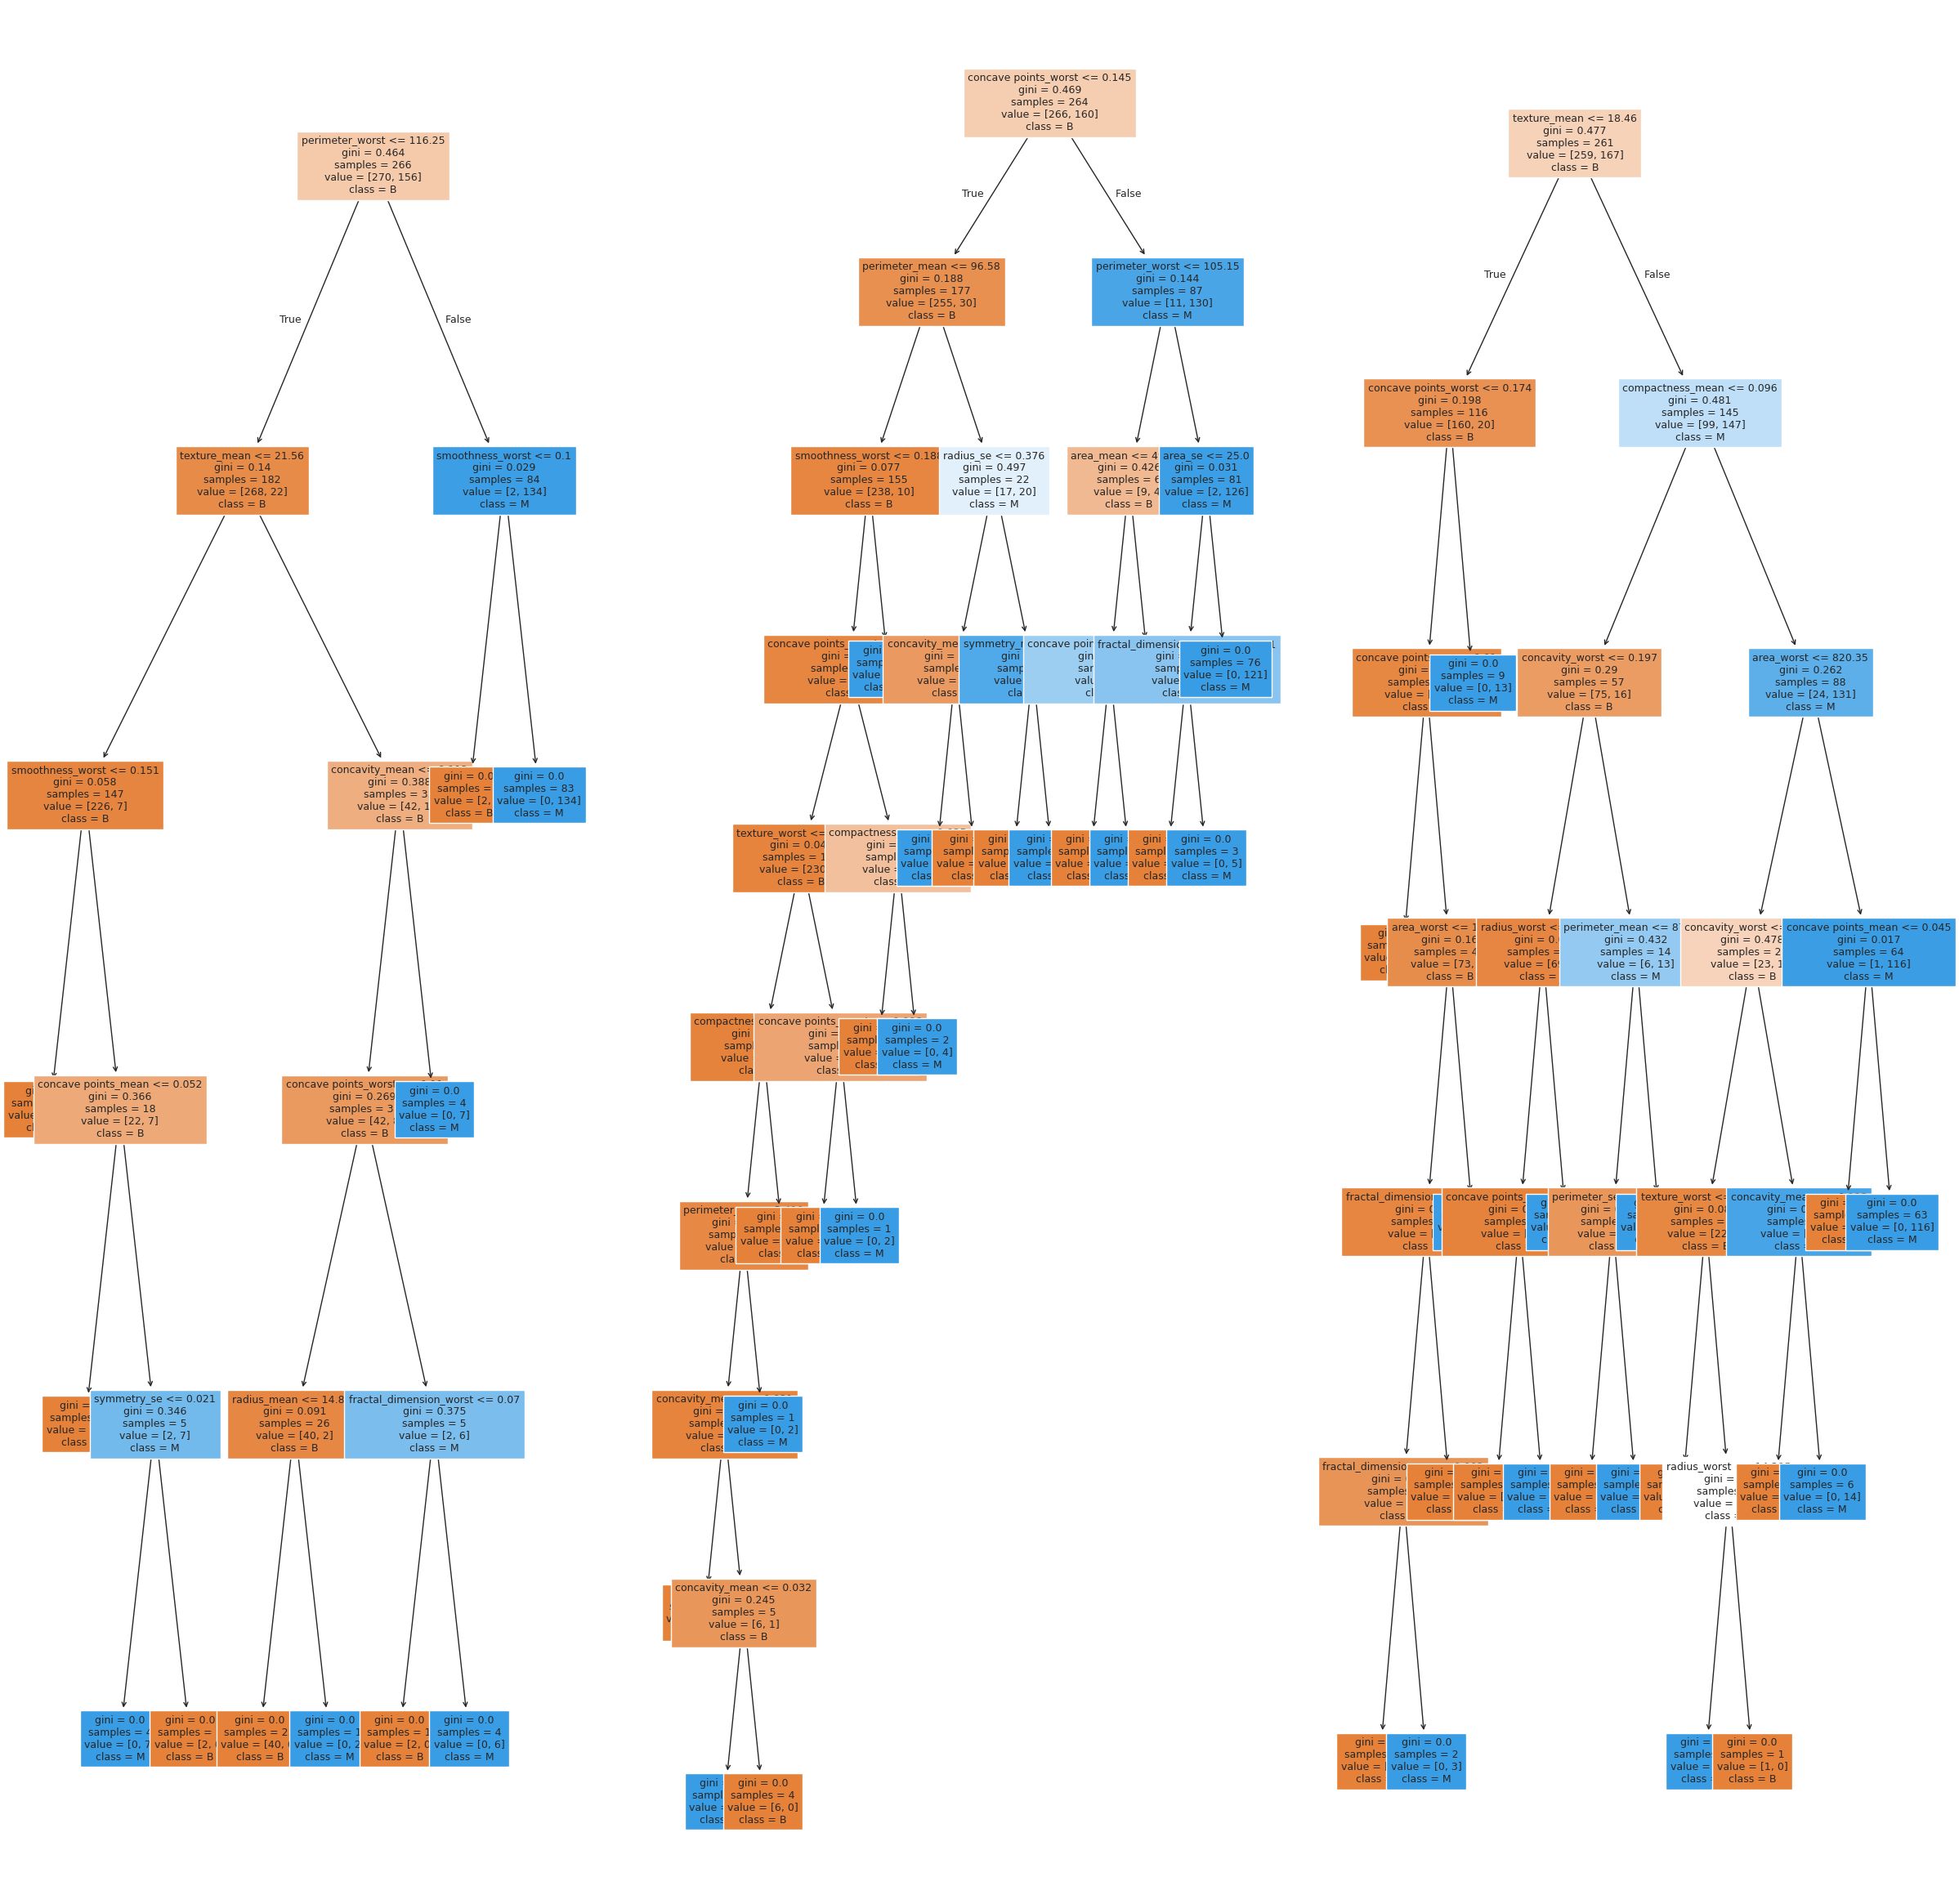

In [31]:
# aqui muda para cada classificador
fig, axs = plt.subplots(1, 3, figsize=(30, 30))

for i, arvore in enumerate(clf.estimators_[:3]):
    plot_tree(
        arvore, 
        ax=axs[i], 
        feature_names=X.columns, 
        class_names=le.classes_, 
        filled=True, 
        fontsize=9
    )

plt.show()

In [32]:
clf.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 'sqrt',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': 42,
 'verbose': 0,
 'warm_start': False}

In [35]:
clf.feature_importances_

array([0.07709983, 0.04734918, 0.12596643, 0.01319209, 0.00543151,
       0.0110316 , 0.09434478, 0.00325577, 0.09184016, 0.03665498,
       0.00621934, 0.02087703, 0.00321625, 0.00579243, 0.00585378,
       0.0719491 , 0.00893069, 0.12088983, 0.02220022, 0.02188762,
       0.11520868, 0.00802007, 0.00293644, 0.0144221 , 0.00338043,
       0.0035535 , 0.01747669, 0.01511129, 0.00843188, 0.0174763 ])

In [36]:
clf.feature_names_in_

array(['area_mean', 'area_se', 'area_worst', 'compactness_mean',
       'compactness_se', 'compactness_worst', 'concave points_mean',
       'concave points_se', 'concave points_worst', 'concavity_mean',
       'concavity_se', 'concavity_worst', 'fractal_dimension_mean',
       'fractal_dimension_se', 'fractal_dimension_worst',
       'perimeter_mean', 'perimeter_se', 'perimeter_worst', 'radius_mean',
       'radius_se', 'radius_worst', 'smoothness_mean', 'smoothness_se',
       'smoothness_worst', 'symmetry_mean', 'symmetry_se',
       'symmetry_worst', 'texture_mean', 'texture_se', 'texture_worst'],
      dtype=object)

In [37]:
pd.Series(
    clf.feature_importances_,
    index=clf.feature_names_in_
).sort_values(ascending=False)

area_worst                 0.125966
perimeter_worst            0.120890
radius_worst               0.115209
concave points_mean        0.094345
concave points_worst       0.091840
area_mean                  0.077100
perimeter_mean             0.071949
area_se                    0.047349
concavity_mean             0.036655
radius_mean                0.022200
radius_se                  0.021888
concavity_worst            0.020877
symmetry_worst             0.017477
texture_worst              0.017476
texture_mean               0.015111
smoothness_worst           0.014422
compactness_mean           0.013192
compactness_worst          0.011032
perimeter_se               0.008931
texture_se                 0.008432
smoothness_mean            0.008020
concavity_se               0.006219
fractal_dimension_worst    0.005854
fractal_dimension_se       0.005792
compactness_se             0.005432
symmetry_se                0.003554
symmetry_mean              0.003380
concave points_se          0

<Axes: >

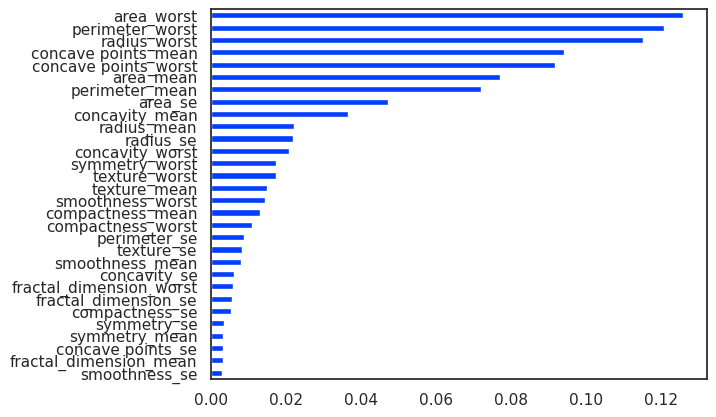

In [38]:
pd.Series(
    clf.feature_importances_,
    index=clf.feature_names_in_
).sort_values(ascending=True).plot.barh()

In [39]:
perm_imp = permutation_importance(
    clf,
    X_test,
    y_test,
    n_repeats=10,
    random_state=RANDOM_STATE
)

In [40]:
perm_imp

{'importances_mean': array([-0.00769231, -0.0034965 , -0.0006993 , -0.0020979 ,  0.        ,
         0.00559441, -0.0034965 ,  0.        ,  0.0041958 , -0.0006993 ,
         0.        ,  0.00699301,  0.        ,  0.        ,  0.        ,
        -0.0041958 , -0.0006993 ,  0.0020979 ,  0.        , -0.0013986 ,
        -0.0006993 , -0.0020979 ,  0.        ,  0.0034965 ,  0.        ,
         0.        , -0.0020979 ,  0.0006993 ,  0.        ,  0.00839161]),
 'importances_std': array([0.00580883, 0.0034965 , 0.00730091, 0.0032046 , 0.        ,
        0.00523309, 0.00469105, 0.        , 0.00342586, 0.00580883,
        0.        , 0.00541676, 0.        , 0.        , 0.        ,
        0.00342586, 0.0020979 , 0.00830374, 0.        , 0.0027972 ,
        0.00730091, 0.0032046 , 0.        , 0.0034965 , 0.        ,
        0.        , 0.0032046 , 0.00659719, 0.        , 0.0041958 ]),
 'importances': array([[-0.01398601, -0.01398601, -0.01398601,  0.        , -0.00699301,
          0.        , 

In [41]:
perm_imp.importances

array([[-0.01398601, -0.01398601, -0.01398601,  0.        , -0.00699301,
         0.        , -0.00699301, -0.01398601,  0.        , -0.00699301],
       [ 0.        , -0.00699301, -0.00699301, -0.00699301,  0.        ,
         0.        , -0.00699301,  0.        ,  0.        , -0.00699301],
       [-0.01398601, -0.00699301,  0.        ,  0.00699301, -0.00699301,
         0.        ,  0.        ,  0.        ,  0.01398601,  0.        ],
       [ 0.        , -0.00699301,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        , -0.00699301,  0.        , -0.00699301],
       [ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.00699301,  0.        ,  0.01398601,  0.01398601,  0.        ,
         0.00699301,  0.00699301,  0.        ,  0.00699301,  0.        ],
       [-0.00699301, -0.00699301, -0.00699301,  0.        , -0.00699301,
         0.00699301,  0.        , -0.00699301

In [42]:
perm_imp.importances_mean.argsort()

array([ 0, 15,  1,  6,  3, 26, 21, 19,  2,  9, 20, 16, 25, 24, 22, 18, 14,
       13, 12, 10,  7,  4, 28, 27, 17, 23,  8,  5, 11, 29])

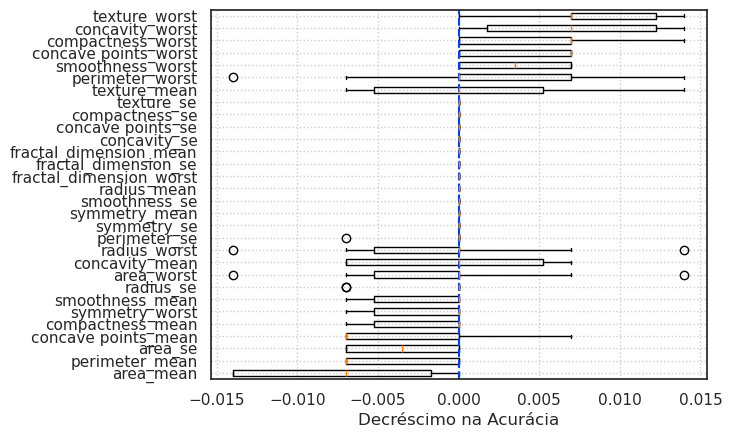

In [43]:
fig, ax = plt.subplots()

ordem = perm_imp.importances_mean.argsort()

ax.boxplot(perm_imp.importances[ordem].T, vert=False, tick_labels=X.columns[ordem])
ax.axvline(x=0, linestyle="--")
ax.set_xlabel("Decréscimo na Acurácia")
ax.grid(True, linestyle=":")

plt.show()